# Milestone 3: RFM Feature Engineering & Distribution Analysis
**Objective:** Extract Recency, Frequency, and Monetary metrics for all 8,800 customers from PostgreSQL and analyze their behavioral distributions.

In [1]:
import ssl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pg8000

# 1. Establish secure SSL connection
ssl_context = ssl.create_default_context()
ssl_context.check_hostname = False
ssl_context.verify_mode = ssl.CERT_NONE

conn = pg8000.connect(
    user="ecom_ro_user",
    password="work-experience-read-only",
    host="ep-bold-hall-azhf2f45-pooler.c-3.ap-southeast-1.aws.neon.tech",
    database="neondb",
    port=5432,
    ssl_context=ssl_context
)

# 2. RFM Feature Engineering Query
# Reference date set to 2026-06-15 (one day after max order date of June 14, 2026)
rfm_query = """
WITH max_date AS (
    SELECT MAX(created_at::date) + INTERVAL '1 day' AS ref_date
    FROM ecom.orders
)
SELECT 
    customer_id,
    (SELECT ref_date FROM max_date)::date - MAX(created_at::date) AS recency_days,
    COUNT(order_id) AS frequency,
    SUM(total) AS monetary
FROM ecom.orders
GROUP BY customer_id;
"""

df_rfm = pd.read_sql(rfm_query, con=conn)

# View summary statistics
display(df_rfm.describe())
df_rfm.head()

,customer_id,recency_days,frequency,monetary
count,8800.000000,8800.000000,8800.000000,8.800000e+03
mean,5022.968409,38.840455,4.545455,3.394933e+04
std,2884.625415,25.941957,9.893442,7.797525e+04
min,1.000000,1.000000,1.000000,1.758200e+02
25%,2529.500000,16.000000,1.000000,3.773640e+03
50%,5038.500000,34.000000,1.000000,1.167846e+04
75%,7521.250000,63.000000,5.000000,3.824318e+04
max,10000.000000,91.000000,178.000000,1.459762e+06


,customer_id,recency_days,frequency,monetary
0,6114,16,1,4835.64
1,4790,74,2,14033.74
2,273,43,1,3065.64
3,3936,72,5,41818.02
4,5761,44,6,51488.12


### Visualizing RFM Distributions
Let's plot histograms for Recency, Frequency, and Monetary values to inspect skewness and identify natural customer segments.

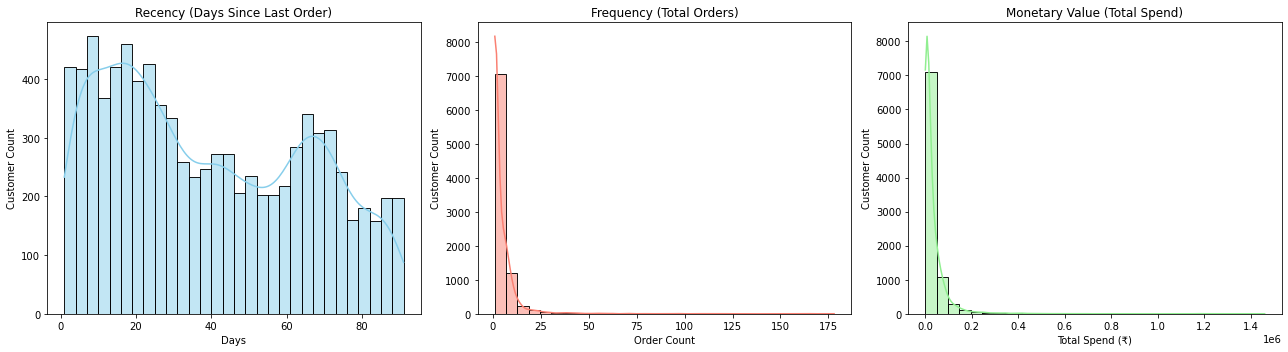

In [2]:
# Set up visualization grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Recency Distribution
sns.histplot(df_rfm['recency_days'], bins=30, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('Recency (Days Since Last Order)')
axes[0].set_xlabel('Days')
axes[0].set_ylabel('Customer Count')

# 2. Frequency Distribution
sns.histplot(df_rfm['frequency'], bins=30, ax=axes[1], color='salmon', kde=True)
axes[1].set_title('Frequency (Total Orders)')
axes[1].set_xlabel('Order Count')
axes[1].set_ylabel('Customer Count')

# 3. Monetary Distribution
sns.histplot(df_rfm['monetary'], bins=30, ax=axes[2], color='lightgreen', kde=True)
axes[2].set_title('Monetary Value (Total Spend)')
axes[2].set_xlabel('Total Spend (₹)')
axes[2].set_ylabel('Customer Count')

plt.tight_layout()
plt.show()